In [4]:
import osmnx as ox

In [5]:
query = "Jakarta, Indonesia"

#geojson from arcgis layer
kecamatan_jakarta_geojson = r"C:\Users\Jorge William\Geopandas\data\kecamatan_jakarta.geojson"

In [6]:
import geopandas as gpd

jakarta = gpd.read_file(kecamatan_jakarta_geojson)

In [7]:
jakarta.head()

,fid,shape__len,shape__are,wadmkk,luaswh,kdcpum,kdpkab,SHAPE__Length,wadmkc,SHAPE__Area,srs_id,geometry
0,1,2175.768467,8.329072e+04,JAKARTA UTARA,8.33,3100,310,2175.768467,PENJARINGAN,8.329072e+04,32748,"MULTIPOLYGON (((106.79489 -6.1333, 106.79489 -..."
1,2,13226.423150,7.520752e+06,JAKARTA PUSAT,751.92,317101,3171,13226.423150,GAMBIR,7.520752e+06,32748,"POLYGON ((106.80162 -6.15984, 106.80161 -6.159..."
2,3,15947.408385,6.175383e+06,JAKARTA PUSAT,617.40,317102,3171,15947.408385,SAWAH BESAR,6.175383e+06,32748,"POLYGON ((106.83303 -6.14156, 106.83297 -6.141..."
3,4,13704.820255,7.174730e+06,JAKARTA PUSAT,717.30,317103,3171,13704.820255,KEMAYORAN,7.174730e+06,32748,"POLYGON ((106.84462 -6.15305, 106.84434 -6.152..."
4,5,13875.258590,4.350701e+06,JAKARTA PUSAT,434.97,317104,3171,13875.258590,SENEN,4.350701e+06,32748,"POLYGON ((106.84869 -6.16815, 106.84861 -6.168..."


In [8]:
m = jakarta.explore()

m.save("jakarta_map.html")

In [9]:
#drop kepulauan seribu from our map
jakarta = jakarta[jakarta["wadmkk"] != "KAB.ADM.KEP.SERIBU"]

n = jakarta.explore()
n.save("jakarta_map2.html")

In [10]:
#check our data CRS -> EPSG:4326
jakarta.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [11]:
jakarta_boundary = jakarta.dissolve()

m = jakarta_boundary.explore()
m.save("jakarta_map_dissolved.html")

In [12]:
import rasterio
import matplotlib.pyplot as plt
from rasterio.mask import mask

indonesia_raster = r"C:\Users\Jorge William\Geopandas\data\indonesia_population_raster.tif"

In [13]:
rasterio.open(indonesia_raster).crs

CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]')

In [14]:
with rasterio.open(indonesia_raster) as src:
    jakarta_boundary = jakarta_boundary.to_crs(src.crs)
    print(src.count)

1


In [15]:
with rasterio.open(indonesia_raster) as src:

    clipped_image, clipped_transform = mask(
        src,
        jakarta_boundary.geometry,
        crop=True,
        nodata=src.nodata
    )

    clipped_meta = src.meta.copy()

    clipped_meta.update({
        "driver": "GTiff",
        "height": clipped_image.shape[1],
        "width": clipped_image.shape[2],
        "transform": clipped_transform,
        "compress": "lzw"
    })

In [16]:
jakarta_raster = r"C:\Users\Jorge William\Geopandas\data\jakarta_raster.tif"

with rasterio.open(jakarta_raster, "w", **clipped_meta) as dst:
    dst.write(clipped_image)

In [ ]:
with rasterio.open(jakarta_raster) as src:
      population = src.read(1, masked=True)

Number of people in this pixel:  167.37314


<function matplotlib.pyplot.show(close=None, block=None)>

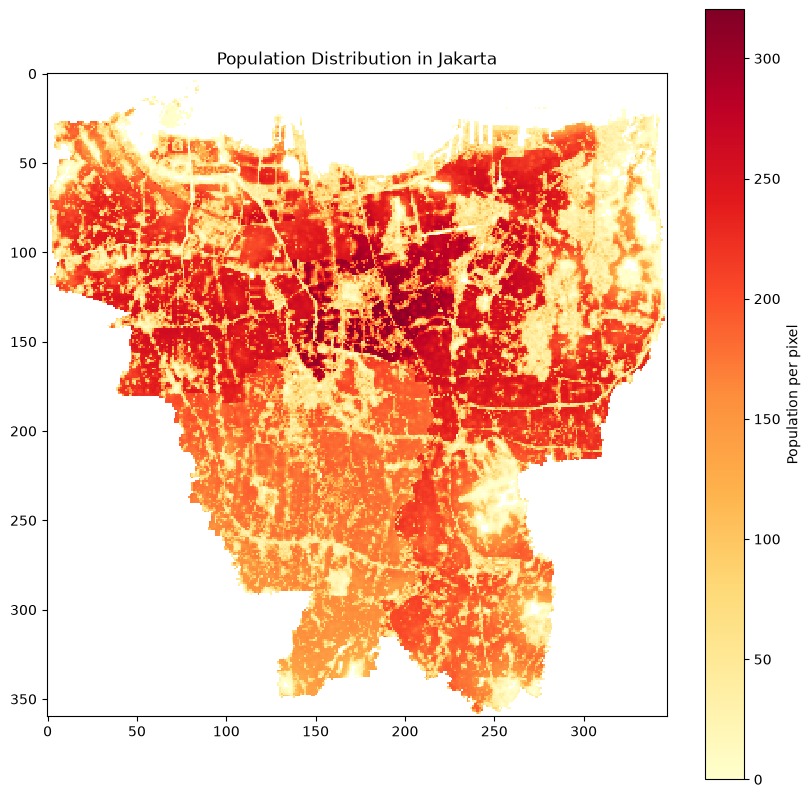

In [18]:
plt.figure(figsize=(10,10))

plt.imshow(
    population,
    cmap="YlOrRd",
    interpolation="nearest"
)

plt.colorbar(label="Population per pixel")
plt.title("Population Distribution in Jakarta")
plt.show

In [19]:
import geopandas as gpd
import osmnx as ox

jakarta_boundary_polygon = jakarta_boundary.geometry.union_all()
#we will obtain the objects from OSM
hospitals = ox.features_from_polygon(
    jakarta_boundary_polygon,
    tags={
        "amenity": ["hospital"],
        "healthcare": ["hospital"]
    }
)

hospitals.to_file(
    "data/jakarta_hospitals.geojson",
    driver="GeoJSON"
)

In [ ]:
malls = ox.features_from_polygon(
    jakarta_boundary_polygon,
    tags={
        "amenity": ["mall"],
    }
)

malls.to_file(
    "data/jakarta_malls.geojson",
    driver="GeoJSON"
)

In [25]:
malls2 = ox.features_from_polygon(
    jakarta_boundary_polygon,
    tags={
        "building": ["mall"]
    }
)

malls2.to_file(
    "data/jakarta_malls2.geojson",
    driver="GeoJSON"
)

In [21]:

schools = ox.features_from_polygon(
    jakarta_boundary_polygon,
    tags={
        "amenity": ["school", "kindergarten",
                    "university", "college"]
    }
)

schools.to_file(
    "data/jakarta_schools.geojson",
    driver="GeoJSON"
)

geopandas.geodataframe.GeoDataFrame